# A 3D pouch cell DFN with tabs

PyBaMM's [pouch cell model](./pouch-cell-model.ipynb) resolves the current collectors in the plane of the cell but treats the electrodes and separator with a 1D DFN at each point, an asymptotic reduction that holds while the cell is thin and the current collectors are good conductors. `BasicDFNUnstructured` goes one step further and solves the DFN on a full 3D mesh of the electrodes and separator, but has no current collectors or tabs.

In this notebook we build a 3D pouch cell DFN by hand that resolves all five layers, the negative current collector, negative electrode, separator, positive electrode and positive current collector, with a tab on top of each current collector. Every layer is meshed with hexahedra, discretised with the unstructured finite volume method `pybamm.FiniteVolumeUnstructured`, and coupled to a 3D heat equation, so the tabs carry both the current and the heat out of the cell.

The model is written from scratch on a `pybamm.BaseModel`, so it is also a worked example of writing a custom 3D model:

1. build one `pybamm.UnstructuredSubMesh` per layer and tag the faces where boundary conditions apply,
2. write the DFN and heat equations on those domains,
3. discretise, solve with `pybamm.IDAKLUSolver`, and plot the solution.

In [1]:
%pip install "pybamm[plot,cite]" -q    # install PyBaMM if it is not installed
import itertools

import matplotlib.pyplot as plt
import numpy as np

import pybamm
from pybamm.meshes.unstructured_submesh import _hex_grid

## Geometry

We use the `Marquis2019` parameter set, which describes a single-layer pouch cell. The layer thicknesses set the through-cell ($x$) coordinates of the five layers, and the electrode width ($y$) and height ($z$) set the size of the cell. Each tab sits on top of its current collector, spans the tab width given by the parameter set, and is 1 cm tall.

In [2]:
parameter_values = pybamm.ParameterValues("Marquis2019")
param = pybamm.LithiumIonParameters()


def value(symbol):
    return float(parameter_values.evaluate(symbol))


L_y = value(param.L_y)
L_z = value(param.L_z)
tab_height = 0.01

# through-cell edges of the five layers: neg CC | neg | sep | pos | pos CC
x_edges = np.cumsum(
    [
        0,
        value(param.n.L_cc),
        value(param.n.L),
        value(param.s.L),
        value(param.p.L),
        value(param.p.L_cc),
    ]
)


def tab_span(electrode):
    centre, width = value(electrode.centre_y_tab), value(electrode.L_tab)
    return centre - width / 2, centre + width / 2


tab_n = tab_span(param.n)
tab_p = tab_span(param.p)
tab_width_p = tab_p[1] - tab_p[0]

print(f"cell: {x_edges[-1] * 1e6:.0f} um thick, {L_y * 1e3:.0f} x {L_z * 1e3:.0f} mm")
print(f"negative tab: y = {tab_n[0] * 1e3:.0f} to {tab_n[1] * 1e3:.0f} mm")
print(f"positive tab: y = {tab_p[0] * 1e3:.0f} to {tab_p[1] * 1e3:.0f} mm")

cell: 275 um thick, 207 x 137 mm
negative tab: y = 40 to 80 mm
positive tab: y = 127 to 167 mm


## Mesh

Each layer gets its own hexahedral mesh. Neighbouring layers must share their interface nodes, so all five meshes use the same $y$ and $z$ edges, and the $y$ edges include the tab edges so that each tab lines up with the cells below it. The cell is about 0.3 mm thick and 200 mm across, so the through-cell direction needs far fewer cells than its aspect ratio suggests: a few per layer resolve the through-cell gradients.

In [3]:
n_x = {"current collector": 2, "electrode": 4, "separator": 3}
n_y_per_span = 2
n_z_body, n_z_tab = 10, 3

y_knots = np.unique([0, *tab_n, *tab_p, L_y])
y_edges = np.unique(
    np.concatenate(
        [np.linspace(a, b, n_y_per_span + 1) for a, b in itertools.pairwise(y_knots)]
    )
)
z_edges = np.linspace(0, L_z, n_z_body + 1)
z_edges_tab = np.linspace(L_z, L_z + tab_height, n_z_tab + 1)


def layer_x_edges(i, n):
    return np.linspace(x_edges[i], x_edges[i + 1], n + 1)

The electrodes and separator are boxes, so `detect_box_boundaries` tags their six faces `"left"`, `"right"` (the $x$ faces), `"front"`, `"back"` ($y$) and `"bottom"`, `"top"` ($z$).

In [4]:
electrode_meshes = {}
for name, i, n in [
    ("negative electrode", 1, n_x["electrode"]),
    ("separator", 2, n_x["separator"]),
    ("positive electrode", 3, n_x["electrode"]),
]:
    mesh = pybamm.UnstructuredSubMesh(*_hex_grid(layer_x_edges(i, n), y_edges, z_edges))
    mesh.detect_box_boundaries()
    electrode_meshes[name] = mesh

A current collector is a box with a tab on top. We mesh the bounding box of both, keep the hexahedra that lie in the body or under the tab, and drop the nodes no remaining hexahedron uses.

The tab needs its own face tags: `"tab_top"` is where the current enters or leaves the cell, and the tab's side faces get `"tab_left"`, `"tab_right"`, `"tab_front"` and `"tab_back"`, so that the box tags only cover the body.

In [5]:
def current_collector_mesh(x_edges_cc, tab):
    nodes, elements = _hex_grid(
        x_edges_cc, y_edges, np.concatenate([z_edges, z_edges_tab[1:]])
    )
    centroids = nodes[elements].mean(axis=1)
    in_body = centroids[:, 2] < L_z
    under_tab = (centroids[:, 1] > tab[0]) & (centroids[:, 1] < tab[1])
    used, elements = np.unique(elements[in_body | under_tab], return_inverse=True)
    mesh = pybamm.UnstructuredSubMesh(nodes[used], elements.reshape(-1, 8))

    first_boundary_face = mesh._boundary_face_start
    x, y, z = mesh.face_centroids[first_boundary_face:].T
    in_tab = z > L_z

    def on(coordinate, position):
        return np.isclose(coordinate, position, rtol=0, atol=1e-10)

    masks = {
        "left": on(x, x_edges_cc[0]) & ~in_tab,
        "right": on(x, x_edges_cc[-1]) & ~in_tab,
        "front": on(y, 0),
        "back": on(y, L_y),
        "bottom": on(z, 0),
        "top": on(z, L_z),
        "tab_left": on(x, x_edges_cc[0]) & in_tab,
        "tab_right": on(x, x_edges_cc[-1]) & in_tab,
        "tab_front": on(y, tab[0]) & in_tab,
        "tab_back": on(y, tab[1]) & in_tab,
        "tab_top": on(z, L_z + tab_height),
    }
    mesh.boundary_faces = {
        tag: np.flatnonzero(mask) + first_boundary_face for tag, mask in masks.items()
    }
    return mesh


meshes = {
    "negative current collector": current_collector_mesh(
        layer_x_edges(0, n_x["current collector"]), tab_n
    ),
    **electrode_meshes,
    "positive current collector": current_collector_mesh(
        layer_x_edges(4, n_x["current collector"]), tab_p
    ),
}

`pybamm.compute_interface_data` matches the `"right"` faces of each layer to the `"left"` faces of the next, which is how fluxes cross from one domain to the next when the layers are concatenated.

In [6]:
names = list(meshes)
for left, right in itertools.pairwise(names):
    pybamm.compute_interface_data(meshes[left], meshes[right], left, right)

for name, mesh in meshes.items():
    print(f"{name}: {mesh.npts} cells")
print(
    "negative current collector tags:",
    {
        tag: len(faces)
        for tag, faces in meshes["negative current collector"].boundary_faces.items()
    },
)

negative current collector: 212 cells
negative electrode: 400 cells
separator: 300 cells
positive electrode: 400 cells
positive current collector: 212 cells
negative current collector tags: {'left': 100, 'right': 100, 'front': 20, 'back': 20, 'bottom': 20, 'top': 16, 'tab_left': 6, 'tab_right': 6, 'tab_front': 6, 'tab_back': 6, 'tab_top': 4}


The meshes are already built, so the mesh generator handed to `pybamm.Mesh` for each layer simply returns it.

In [7]:
class PrebuiltMeshGenerator(pybamm.MeshGenerator):
    def __init__(self, mesh):
        self._mesh = mesh
        super().__init__(pybamm.UnstructuredSubMesh)

    def __call__(self, lims, npts):
        return self._mesh

## Model

### Variables

Each layer has its own $x$, $y$, $z$ coordinates. The solid potential lives in the solid phase, so the negative one spans the negative current collector and electrode, and the positive one the positive electrode and current collector. The electrolyte spans the two electrodes and the separator, and the temperature spans all five layers. Each of these is a concatenation of one variable per layer.

In [8]:
model = pybamm.BaseModel(name="3D pouch cell DFN")

short_names = {
    "negative current collector": "ncc",
    "negative electrode": "n",
    "separator": "s",
    "positive electrode": "p",
    "positive current collector": "pcc",
}
coordinates = {
    domain: [
        pybamm.SpatialVariable(
            f"{axis}_{short}", domain=domain, coord_sys="cartesian", direction=direction
        )
        for axis, direction in zip("xyz", ("lr", "fb", "tb"), strict=True)
    ]
    for domain, short in short_names.items()
}
x_n, _, z_n = coordinates["negative electrode"]
x_s, _, z_s = coordinates["separator"]
x_p, _, z_p = coordinates["positive electrode"]

Q = pybamm.Variable("Discharge capacity [A.h]")

phi_s_ncc = pybamm.Variable(
    "Negative current collector potential [V]", domain="negative current collector"
)
phi_s_n_electrode = pybamm.Variable(
    "Negative electrode potential [V]", domain="negative electrode"
)
phi_s_n = pybamm.concatenation(phi_s_ncc, phi_s_n_electrode)
phi_s_p_electrode = pybamm.Variable(
    "Positive electrode potential [V]", domain="positive electrode"
)
phi_s_pcc = pybamm.Variable(
    "Positive current collector potential [V]", domain="positive current collector"
)
phi_s_p = pybamm.concatenation(phi_s_p_electrode, phi_s_pcc)

c_e_n, c_e_s, c_e_p = (
    pybamm.Variable(
        f"{name.capitalize()} electrolyte concentration [mol.m-3]", domain=name
    )
    for name in ("negative electrode", "separator", "positive electrode")
)
c_e = pybamm.concatenation(c_e_n, c_e_s, c_e_p)
phi_e_n, phi_e_s, phi_e_p = (
    pybamm.Variable(f"{name.capitalize()} electrolyte potential [V]", domain=name)
    for name in ("negative electrode", "separator", "positive electrode")
)
phi_e = pybamm.concatenation(phi_e_n, phi_e_s, phi_e_p)

c_s_n = pybamm.Variable(
    "Negative particle concentration [mol.m-3]",
    domain="negative particle",
    auxiliary_domains={"secondary": "negative electrode"},
)
c_s_p = pybamm.Variable(
    "Positive particle concentration [mol.m-3]",
    domain="positive particle",
    auxiliary_domains={"secondary": "positive electrode"},
)

T_ncc, T_n, T_s, T_p, T_pcc = (
    pybamm.Variable(f"{name.capitalize()} temperature [K]", domain=name)
    for name in short_names
)
T = pybamm.concatenation(T_ncc, T_n, T_s, T_p, T_pcc)
T_e = pybamm.concatenation(T_n, T_s, T_p)

### Current, porosity and reactions

The cell is discharged at the parameter set's current (1C) for 30 minutes and then rests; including 1800 s in `t_eval` makes the solver stop at the step in current rather than step across it. The porosity and active material volume fraction are `FunctionParameter`s of the through-cell and vertical position ($x$ and $z$), so they could vary over the cell; `Marquis2019` makes them uniform. The reaction rate is Butler–Volmer kinetics, as in the DFN.

In [9]:
discharging = pybamm.t < 1800
current = param.current_with_time * discharging
i_cell = param.current_density_with_time * discharging


def function_of_position(name, x, z):
    return pybamm.FunctionParameter(
        name, {"Through-cell distance (x) [m]": x, "Vertical distance (z) [m]": z}
    )


eps_n = function_of_position("Negative electrode porosity", x_n, z_n)
eps_s = function_of_position("Separator porosity", x_s, z_s)
eps_p = function_of_position("Positive electrode porosity", x_p, z_p)
eps = pybamm.concatenation(eps_n, eps_s, eps_p)
eps_s_n = function_of_position(
    "Negative electrode active material volume fraction", x_n, z_n
)
eps_s_p = function_of_position(
    "Positive electrode active material volume fraction", x_p, z_p
)
tortuosity = pybamm.concatenation(
    eps_n**param.n.b_e, eps_s**param.s.b_e, eps_p**param.p.b_e
)


def butler_volmer(electrode, c_s, c_e, phi_s, phi_e, T):
    c_s_surf = pybamm.surf(c_s)
    sto_surf = c_s_surf / electrode.prim.c_max
    eta = phi_s - phi_e - electrode.prim.U(sto_surf, T)
    j0 = electrode.prim.j0(c_e, c_s_surf, T)
    j = 2 * j0 * pybamm.sinh(electrode.prim.ne / 2 * param.F * eta / (param.R * T))
    return j, eta, sto_surf


j_n, eta_n, sto_surf_n = butler_volmer(
    param.n, c_s_n, c_e_n, phi_s_n_electrode, phi_e_n, T_n
)
j_p, eta_p, sto_surf_p = butler_volmer(
    param.p, c_s_p, c_e_p, phi_s_p_electrode, phi_e_p, T_p
)
a_j_n = 3 * param.n.prim.epsilon_s_av / param.n.prim.R_typ * j_n
a_j_p = 3 * param.p.prim.epsilon_s_av / param.p.prim.R_typ * j_p
a_j = pybamm.concatenation(a_j_n, pybamm.PrimaryBroadcast(0, "separator"), a_j_p)


def broadcast_zero(domain):
    return pybamm.PrimaryBroadcast(pybamm.Scalar(0), domain)

### Boundary conditions

Boundary conditions are keyed by the face tags from the mesh. Most faces are insulated, so we write a helper that sets a zero flux on every listed face and lets us override the few that are not.

In [10]:
BOX_FACES = ["left", "right", "front", "back", "bottom", "top"]
TAB_FACES = ["tab_left", "tab_right", "tab_front", "tab_back", "tab_top"]


def zero_flux_except(faces, **conditions):
    return {face: (pybamm.Scalar(0), "Neumann") for face in faces} | conditions

### Particles and discharge capacity

Lithium diffuses in spherical particles at every point of each electrode, driven by the local reaction at the particle surface.

In [11]:
model.rhs[Q] = current / 3600
model.initial_conditions[Q] = pybamm.Scalar(0)

for c_s, j, T_electrode, electrode in [
    (c_s_n, j_n, T_n, param.n),
    (c_s_p, j_p, T_p, param.p),
]:
    T_particle = pybamm.PrimaryBroadcast(T_electrode, c_s.domain)
    D = electrode.prim.D(c_s, T_particle)
    model.rhs[c_s] = pybamm.div(D * pybamm.grad(c_s))
    model.boundary_conditions[c_s] = {
        "left": (pybamm.Scalar(0), "Neumann"),
        "right": (-j / (param.F * pybamm.surf(D)), "Neumann"),
    }
    model.initial_conditions[c_s] = electrode.prim.c_init

### Solid potential

Charge conservation in the solid phase holds across each current collector and its electrode, with the effective electrode conductivity in the electrode and the current collector conductivity in the current collector. The negative tab is grounded, and the cell current is drawn through the top of the positive tab, scaled by the ratio of the electrode area to the tab cross-section. The equations are multiplied by a length scale so that their residuals are of order one.

In [12]:
length_scale = param.L_x**2 * param.L_z**2

sigma_n = pybamm.concatenation(
    pybamm.PrimaryBroadcast(param.n.sigma_cc, "negative current collector"),
    param.n.sigma(None, T_n) * eps_s_n**param.n.b_s,
)
source_n = pybamm.concatenation(broadcast_zero("negative current collector"), a_j_n)
model.algebraic[phi_s_n] = length_scale * (
    pybamm.div(-sigma_n * pybamm.grad(phi_s_n)) + source_n
)
model.boundary_conditions[phi_s_n] = zero_flux_except(
    BOX_FACES + TAB_FACES, tab_top=(pybamm.Scalar(0), "Dirichlet")
)
model.initial_conditions[phi_s_n] = pybamm.Scalar(0)

sigma_p = pybamm.concatenation(
    param.p.sigma(None, T_p) * eps_s_p**param.p.b_s,
    pybamm.PrimaryBroadcast(param.p.sigma_cc, "positive current collector"),
)
source_p = pybamm.concatenation(a_j_p, broadcast_zero("positive current collector"))
model.algebraic[phi_s_p] = length_scale * (
    pybamm.div(-sigma_p * pybamm.grad(phi_s_p)) + source_p
)
tab_area_p = value(param.p.L_cc) * tab_width_p
tab_current_density = i_cell * L_y * L_z / tab_area_p
model.boundary_conditions[phi_s_p] = zero_flux_except(
    BOX_FACES + TAB_FACES, tab_top=(-tab_current_density / param.p.sigma_cc, "Neumann")
)
model.initial_conditions[phi_s_p] = param.ocv_init

### Electrolyte

The electrolyte equations are the DFN's, now with gradients in all three directions. The electrolyte is sealed inside the cell, so every outer face of the electrodes and separator has zero flux.

In [13]:
kappa_eff = param.kappa_e(c_e, T_e) * tortuosity
model.algebraic[phi_e] = length_scale * (
    pybamm.div(kappa_eff * param.chiRT_over_Fc(c_e, T_e) * pybamm.grad(c_e))
    - pybamm.div(kappa_eff * pybamm.grad(phi_e))
    - a_j
)
model.boundary_conditions[phi_e] = zero_flux_except(BOX_FACES)
model.initial_conditions[phi_e] = -param.n.prim.U_init

model.rhs[c_e] = (1 / eps) * (
    pybamm.div(tortuosity * param.D_e(c_e, T_e) * pybamm.grad(c_e))
    + (1 - param.t_plus(c_e, T_e)) * a_j / param.F
)
model.boundary_conditions[c_e] = zero_flux_except(BOX_FACES)
model.initial_conditions[c_e] = param.c_e_init

### Temperature

Heat is generated by the reactions (irreversible and reversible heating) in the electrodes and conducted through all five layers. For brevity we leave out ohmic heating in the solid, electrolyte and current collectors, so the temperature rise is a lower bound. Each layer has its own density, heat capacity and thermal conductivity. The cell is insulated except at the tabs, whose tops are held at the ambient temperature.

In [14]:
T_init = param.T_init
layer_properties = [
    ("negative current collector", param.n.therm.rho_c_p_cc, param.n.therm.lambda_cc),
    ("negative electrode", param.n.therm.rho_c_p, param.n.therm.lambda_),
    ("separator", param.s.therm.rho_c_p, param.s.therm.lambda_),
    ("positive electrode", param.p.therm.rho_c_p, param.p.therm.lambda_),
    ("positive current collector", param.p.therm.rho_c_p_cc, param.p.therm.lambda_cc),
]
rho_c_p = pybamm.concatenation(
    *(
        pybamm.PrimaryBroadcast(rho_c_p(T_init), domain)
        for domain, rho_c_p, _ in layer_properties
    )
)
thermal_conductivity = pybamm.concatenation(
    *(
        pybamm.PrimaryBroadcast(lambda_(T_init), domain)
        for domain, _, lambda_ in layer_properties
    )
)

Q_reaction = pybamm.concatenation(
    broadcast_zero("negative current collector"),
    a_j_n * (eta_n + T_n * param.n.prim.dUdT(sto_surf_n)),
    broadcast_zero("separator"),
    a_j_p * (eta_p + T_p * param.p.prim.dUdT(sto_surf_p)),
    broadcast_zero("positive current collector"),
)
model.rhs[T] = (
    pybamm.div(thermal_conductivity * pybamm.grad(T)) + Q_reaction
) / rho_c_p
T_amb = param.T_amb(pybamm.Scalar(0), pybamm.Scalar(0), pybamm.t)
model.boundary_conditions[T] = zero_flux_except(
    BOX_FACES + TAB_FACES, tab_top=(T_amb, "Dirichlet")
)
model.initial_conditions[T] = T_init

### Outputs and events

The terminal voltage is the mean positive current collector potential over the top of the positive tab, since the negative tab is at 0 V. `pybamm.BoundaryIntegral` integrates over any tagged set of faces. The simulation stops if the voltage leaves the parameter set's voltage window.

In [15]:
voltage = pybamm.BoundaryIntegral(phi_s_pcc, region="tab_top") / tab_area_p
model.variables = {
    "Time [s]": pybamm.t,
    "Current [A]": current,
    "Voltage [V]": voltage,
    "Discharge capacity [A.h]": Q,
    "Negative current collector potential [V]": phi_s_ncc,
    "Negative electrode potential [V]": phi_s_n_electrode,
    "Positive electrode potential [V]": phi_s_p_electrode,
    "Positive current collector potential [V]": phi_s_pcc,
    "Electrolyte concentration [mol.m-3]": c_e,
    "Electrolyte potential [V]": phi_e,
    "Cell temperature [K]": T,
    "Maximum temperature [K]": pybamm.Max(T),
    "Negative electrode interfacial current density [A.m-2]": j_n,
    "Positive electrode interfacial current density [A.m-2]": j_p,
}
model.events += [
    pybamm.Event("Minimum voltage [V]", voltage - param.voltage_low_cut),
    pybamm.Event("Maximum voltage [V]", param.voltage_high_cut - voltage),
]

## Discretise and solve

The geometry gives the extent of each domain. The five layers use the prebuilt meshes and `pybamm.FiniteVolumeUnstructured`, and the particles use the usual 1D finite volume method.

In [16]:
geometry = {}
for domain, (x, y, z) in coordinates.items():
    i = names.index(domain)
    z_max = L_z + tab_height if "current collector" in domain else L_z
    geometry[domain] = {
        x: {"min": x_edges[i], "max": x_edges[i + 1]},
        y: {"min": 0, "max": L_y},
        z: {"min": 0, "max": z_max},
    }
geometry["negative particle"] = {"r_n": {"min": 0, "max": param.n.prim.R_typ}}
geometry["positive particle"] = {"r_p": {"min": 0, "max": param.p.prim.R_typ}}
geometry["current collector"] = {"z": {"position": 0}}

submesh_types = {domain: PrebuiltMeshGenerator(mesh) for domain, mesh in meshes.items()}
submesh_types["negative particle"] = pybamm.Uniform1DSubMesh
submesh_types["positive particle"] = pybamm.Uniform1DSubMesh
submesh_types["current collector"] = pybamm.SubMesh0D

spatial_methods = {domain: pybamm.FiniteVolumeUnstructured() for domain in meshes}
spatial_methods["negative particle"] = pybamm.FiniteVolume()
spatial_methods["positive particle"] = pybamm.FiniteVolume()
spatial_methods["current collector"] = pybamm.ZeroDimensionalSpatialMethod()

# pybamm.Mesh wants a point count for every coordinate; the prebuilt meshes ignore them
var_pts = {coordinate: 1 for xyz in coordinates.values() for coordinate in xyz}
var_pts.update({"r_n": 10, "r_p": 10})

parameter_values.process_model(model)
parameter_values.process_geometry(geometry)
mesh = pybamm.Mesh(geometry, submesh_types, var_pts)
disc = pybamm.Discretisation(mesh, spatial_methods)
disc.process_model(model)
print(f"{model.len_rhs_and_alg} unknowns")

12949 unknowns


In [17]:
solver = pybamm.IDAKLUSolver(atol=1e-4, rtol=1e-4)
solution = solver.solve(
    model, t_eval=np.array([0, 1800, 3600]), t_interp=np.linspace(0, 3600, 121)
)
print(f"solved in {solution.solve_time}, termination: {solution.termination}")

solved in 12.457 s, termination: final time


## Results

The voltage drops through the discharge and recovers during the rest, while the cell heats up and then cools back towards ambient through the tabs.

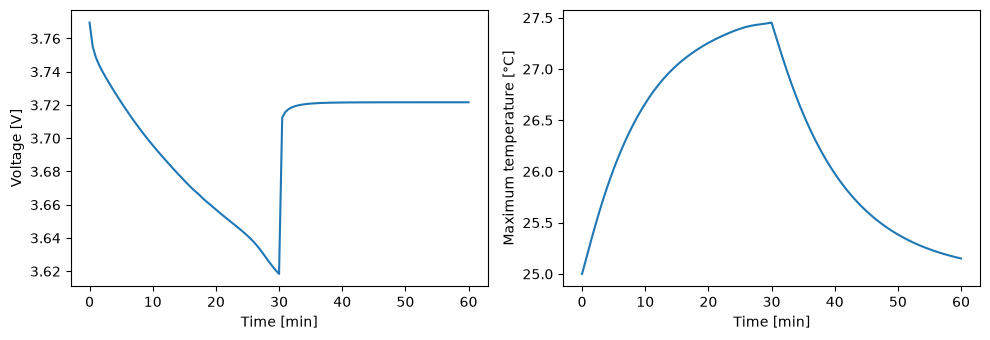

In [18]:
t = solution.t
fig, (ax_voltage, ax_temperature) = plt.subplots(1, 2, figsize=(10, 3.5))
ax_voltage.plot(t / 60, solution["Voltage [V]"](t))
ax_voltage.set_xlabel("Time [min]")
ax_voltage.set_ylabel("Voltage [V]")
ax_temperature.plot(t / 60, solution["Maximum temperature [K]"](t) - 273.15)
ax_temperature.set_xlabel("Time [min]")
ax_temperature.set_ylabel("Maximum temperature [°C]")
fig.tight_layout()

Unstructured-mesh variables can be evaluated at any point with `solution[name](t, x=..., y=..., z=...)`. At the end of the discharge, the hottest part of the cell is the bottom, furthest from the tabs that cool it. Next to the negative current collector, in the first layer of cells of the negative electrode, the reaction is fastest under the tabs and slowest in the bottom corner furthest from them, following the ohmic losses in the current collectors. Points outside a variable's domain, such as the space beside the tab, are NaN and so left blank.

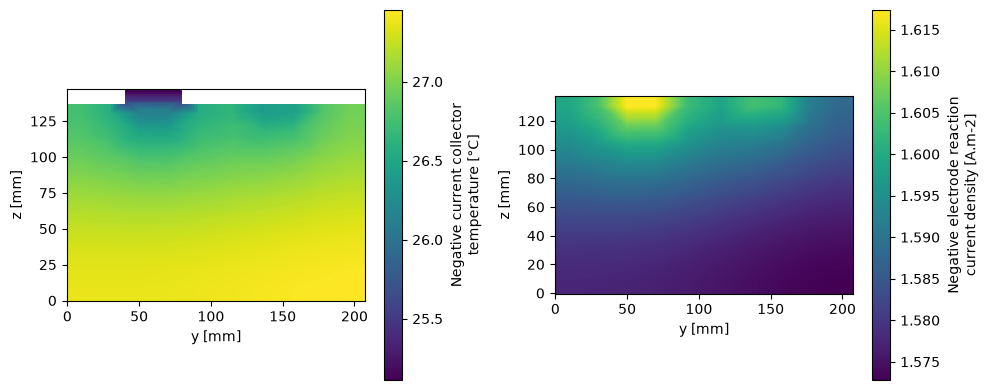

In [19]:
t_end = 1800
y = np.linspace(0, L_y, 200)
z = np.linspace(0, L_z + tab_height, 200)
x_cc = (x_edges[0] + x_edges[1]) / 2
# centre of the first layer of negative electrode cells, next to the current collector
x_n_cc_side = x_edges[1] + (x_edges[2] - x_edges[1]) / (2 * n_x["electrode"])

temperature = solution["Cell temperature [K]"](t_end, x=x_cc, y=y, z=z)[0] - 273.15
reaction = solution["Negative electrode interfacial current density [A.m-2]"](
    t_end, x=x_n_cc_side, y=y, z=z[z <= L_z]
)[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, z_plot, label in [
    (axes[0], temperature, z, "Negative current collector\ntemperature [°C]"),
    (
        axes[1],
        reaction,
        z[z <= L_z],
        "Negative electrode reaction\ncurrent density [A.m-2]",
    ),
]:
    image = ax.pcolormesh(y * 1e3, z_plot * 1e3, data.T, shading="auto")
    fig.colorbar(image, ax=ax, label=label)
    ax.set_xlabel("y [mm]")
    ax.set_ylabel("z [mm]")
    ax.set_aspect("equal")
fig.tight_layout()

For an interactive 3D view with a time slider, install the `vtk` extra and run

```python
solution.plot(["Cell temperature [K]", "Electrolyte concentration [mol.m-3]"], backend="vtk")
```

In [20]:
pybamm.print_citations()

[1] Joel A. E. Andersson, Joris Gillis, Greg Horn, James B. Rawlings, and Moritz Diehl. CasADi – A software framework for nonlinear optimization and optimal control. Mathematical Programming Computation, 11(1):1–36, 2019. doi:10.1007/s12532-018-0139-4.
[2] Charles R. Harris, K. Jarrod Millman, Stéfan J. van der Walt, Ralf Gommers, Pauli Virtanen, David Cournapeau, Eric Wieser, Julian Taylor, Sebastian Berg, Nathaniel J. Smith, and others. Array programming with NumPy. Nature, 585(7825):357–362, 2020. doi:10.1038/s41586-020-2649-2.
[3] Alan C. Hindmarsh. The PVODE and IDA algorithms. Technical Report, Lawrence Livermore National Lab., CA (US), 2000. doi:10.2172/802599.
[4] Alan C. Hindmarsh, Peter N. Brown, Keith E. Grant, Steven L. Lee, Radu Serban, Dan E. Shumaker, and Carol S. Woodward. SUNDIALS: Suite of nonlinear and differential/algebraic equation solvers. ACM Transactions on Mathematical Software (TOMS), 31(3):363–396, 2005. doi:10.1145/1089014.1089020.
[5] Scott G. Marquis, Vale